In [ ]:
import pypsa
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
n0 = pypsa.Network("experiment_0/experiment0.nc")
#print(n0.snapshots[0:5])

INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, generators, lines, loads, sub_networks


DatetimeIndex(['2025-01-01 05:00:00', '2025-01-01 06:00:00',
               '2025-01-01 07:00:00', '2025-01-01 08:00:00',
               '2025-01-01 09:00:00'],
              dtype='datetime64[ns]', name='snapshot', freq=None)


In [77]:
K_array = n0.incidence_matrix(branch_components=["Line"]).toarray()

K = K_array.T

reactances = np.array([13, 18, 9, 15, 18, 9, 12, 14])

Rmat = np.diag(1/reactances)

Bmat = K.T @ Rmat @ K
Bred = Bmat[:5, :5]

theta_red = np.linalg.solve(Bred, np.eye(5))
theta_f = np.vstack( (theta_red, np.zeros(5)) )

pt = Rmat @ K @ theta_f


# 2. Wrap into a labeled pandas DataFrame (Rows = Buses, Columns = Lines)
Hmat = pd.DataFrame(
    pt,
    index=n0.lines.index,
    columns=n0.buses.index[:5]
)

print(Hmat)

name               Spring   Topsham      Gulf   Raymond   Trenton
name                                                             
Chester-Trenton -0.556326 -0.588565 -0.469529 -0.571206 -0.660896
Chester-Gulf    -0.443674 -0.411435 -0.530471 -0.428794 -0.339104
Trenton-Gulf    -0.083766  0.027279 -0.382732 -0.032514  0.276418
Trenton-Topsham -0.472560 -0.615844 -0.086797 -0.538691  0.062687
Gulf-Spring     -0.527440 -0.384156  0.086797 -0.461309 -0.062687
Spring-Topsham   0.351045 -0.285373  0.064478  0.057313 -0.046567
Spring-Raymond   0.121515 -0.098783  0.022319 -0.518622 -0.016119
Topsham-Raymond -0.121515  0.098783 -0.022319 -0.481378  0.016119


In [ ]:
times = n0.snapshots

load = n0.loads_t.p_set.loc[times]
load.columns = n0.loads["bus"]
#load.head()

# generator availability
gen_t = n0.generators_t.p_max_pu.loc[times] * n0.generators.loc["wind", "p_nom"]
for energy in list(n0.generators.index)[1:]:
    gen_t[energy] = n0.generators.loc[energy, "p_nom"]
gen_t.columns = n0.generators["bus"]

total_needed = load.sum(axis=1)


dispatch = pd.DataFrame(0, index=gen_t.index, columns=gen_t.columns)
for bus_name in list(gen_t.columns):
    dispatch[bus_name] = np.minimum(total_needed, gen_t[bus_name])
    total_needed = total_needed - dispatch[bus_name]

net_inj = dispatch - load
flow_df = net_inj[Hmat.columns] @ Hmat.T # predicted flow on each line at each time index


In [106]:
# Divide by transmission capacities
limits = n0.lines.s_nom.reindex(flow_df.columns)
util = flow_df.div(limits, axis=1)
overload = (util.abs() - 1).clip(lower=0)
print(
    (100 * (overload > 0).mean())
    .sort_values(ascending=False)
    .round(1)
)

name
Gulf-Spring        11.0
Trenton-Topsham     7.2
Spring-Raymond      4.8
Topsham-Raymond     0.0
Chester-Trenton     0.0
Chester-Gulf        0.0
Trenton-Gulf        0.0
Spring-Topsham      0.0
dtype: float64


In [105]:
line = "Spring-Raymond"

pred = overload[line] > 0

actual = (
    n0.lines_t.mu_upper[line]
    .reindex(pred.index)
    .abs() > 0.01
)

pd.crosstab(
    actual, pred,
    rownames=["Actually binding"],
    colnames=["Predicted overload"]
)

Predicted overload,False,True
Actually binding,,
False,14310,0
True,0,722


In [110]:
spread = (
    n0.buses_t.marginal_price["Spring"]
    - n0.buses_t.marginal_price["Chester"]
)

# Convert to four categorical classes
y = pd.Series(
    pd.Categorical(spread.round(3)).codes,
    index=spread.index,
    name="congestion_class"
)

In [121]:
X_base = load.add_prefix("load_").join(
    gen_t["Chester"].rename("wind_available")
)

X_phys = (
    X_base
    .join(util.add_prefix("util_"))
    .join(overload.add_prefix("overload_"))
)

In [126]:
# Align all three datasets
idx = X_base.index.intersection(
    X_phys.index
).intersection(y.dropna().index).sort_values()

X_base = X_base.loc[idx]
X_phys = X_phys.loc[idx]
y = y.loc[idx].astype(int)

# Chronological split
train = idx.year == 2025
test = idx.year == 2026

In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_A = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="lbfgs",
        max_iter=2000
    )
)

model_A.fit(X_base.loc[train], y.loc[train])

model_B = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="lbfgs",
        max_iter=2000
    )
)

model_B.fit(X_phys.loc[train], y.loc[train])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['load_Spring','load_Topsham','load_Gulf',...,'overload_Spring-Topsham', 'overload_Spring-Raymond','overload_Topsham-Raymond']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [131]:
probs_A = model_A.predict_proba(X_base.loc[test])
probs_B = model_B.predict_proba(X_phys.loc[test])

print(probs_B[:5].round(3))

[[0.001 0.999 0.    0.   ]
 [0.001 0.999 0.    0.   ]
 [0.    1.    0.    0.   ]
 [0.    1.    0.    0.   ]
 [0.    1.    0.    0.   ]]


In [132]:

from sklearn.metrics import accuracy_score, log_loss

for name, model, X in [
    ("Conventional", model_A, X_base),
    ("Physics-informed", model_B, X_phys)
]:
    predictions = model.predict(X.loc[test])
    probabilities = model.predict_proba(X.loc[test])

    print(name)
    print("Accuracy:", round(
        accuracy_score(y.loc[test], predictions), 3
    ))
    print("Log loss:", round(
        log_loss(y.loc[test], probabilities), 3
    ))


Conventional
Accuracy: 0.904
Log loss: 0.235
Physics-informed
Accuracy: 0.99
Log loss: 0.027


In [133]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model, X in [
    ("Conventional", model_A, X_base),
    ("Physics-informed", model_B, X_phys)
]:
    pred = model.predict(X.loc[test])

    print(f"\n{name}")
    print(confusion_matrix(y.loc[test], pred))
    print(classification_report(
        y.loc[test], pred, zero_division=0
    ))


Conventional
[[ 318    7    2    0]
 [   4 5155   24   67]
 [   0   62   70   29]
 [   0  406   20  282]]
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       327
           1       0.92      0.98      0.95      5250
           2       0.60      0.43      0.51       161
           3       0.75      0.40      0.52       708

    accuracy                           0.90      6446
   macro avg       0.81      0.70      0.74      6446
weighted avg       0.89      0.90      0.89      6446


Physics-informed
[[ 311   16    0    0]
 [   0 5249    1    0]
 [   0   12  149    0]
 [   0   35    1  672]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       327
           1       0.99      1.00      0.99      5250
           2       0.99      0.93      0.96       161
           3       1.00      0.95      0.97       708

    accuracy                           0.99      6446
   macro avg       0.

In [135]:
from sklearn.ensemble import HistGradientBoostingClassifier

model_C = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    early_stopping=False,
    random_state=42
)

model_C.fit(X_base.loc[train], y.loc[train])

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [136]:
model_D = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    early_stopping=False,
    random_state=42
)

model_D.fit(X_phys.loc[train], y.loc[train])

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",15
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [137]:
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    classification_report,
    confusion_matrix
)

for name, model, X in [
    ("Conventional GB", model_C, X_base),
    ("Physics-informed GB", model_D, X_phys)
]:
    pred = model.predict(X.loc[test])
    probs = model.predict_proba(X.loc[test])

    print(f"\n{name}")
    print("Accuracy:", round(
        accuracy_score(y.loc[test], pred), 3
    ))
    print("Log loss:", round(
        log_loss(y.loc[test], probs, labels=model.classes_), 3
    ))
    print(classification_report(
        y.loc[test], pred, zero_division=0
    ))
    print(confusion_matrix(y.loc[test], pred))


Conventional GB
Accuracy: 0.951
Log loss: 0.133
              precision    recall  f1-score   support

           0       0.96      0.86      0.90       327
           1       0.96      0.99      0.97      5250
           2       0.81      0.69      0.74       161
           3       0.91      0.79      0.85       708

    accuracy                           0.95      6446
   macro avg       0.91      0.83      0.87      6446
weighted avg       0.95      0.95      0.95      6446

[[ 280   47    0    0]
 [  12 5175   18   45]
 [   0   37  111   13]
 [   0  139    8  561]]

Physics-informed GB
Accuracy: 0.999
Log loss: 0.004
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       327
           1       1.00      1.00      1.00      5250
           2       0.96      0.98      0.97       161
           3       1.00      0.99      0.99       708

    accuracy                           1.00      6446
   macro avg       0.99      0.99      0.99 

In [138]:
# ablation study
# A: Conventional
X_base = load.add_prefix("load_").join(
    gen_t["Chester"].rename("wind_available")
)

# B: Add copper-plate generator dispatch
X_econ = X_base.join(
    dispatch.add_prefix("cp_gen_")
)

# C: Add PTDF-derived transmission features
X_full = (
    X_econ
    .join(util.add_prefix("util_"))
    .join(overload.add_prefix("overload_"))
)

In [139]:
idx = X_full.index.intersection(y.dropna().index).sort_values()

train = idx.year == 2025
test = idx.year == 2026

X_base = X_base.loc[idx]
X_econ = X_econ.loc[idx]
X_full = X_full.loc[idx]
y = y.loc[idx]

In [140]:

from sklearn.ensemble import HistGradientBoostingClassifier

feature_sets = {
    "Conventional": X_base,
    "Economic": X_econ,
    "Physics-informed": X_full
}

models = {}

for name, X in feature_sets.items():
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=15,
        early_stopping=False,
        random_state=42
    )

    model.fit(X.loc[train], y.loc[train])
    models[name] = model


In [141]:
from sklearn.metrics import accuracy_score, log_loss, f1_score

results = []

for name, model in models.items():
    X = feature_sets[name]

    pred = model.predict(X.loc[test])
    probs = model.predict_proba(X.loc[test])

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y.loc[test], pred),
        "Log Loss": log_loss(
            y.loc[test], probs, labels=model.classes_
        ),
        "Macro F1": f1_score(
            y.loc[test], pred, average="macro"
        )
    })

pd.DataFrame(results).set_index("Model").round(4)

,Accuracy,Log Loss,Macro F1
Model,,,
Conventional,0.9505,0.1332,0.8668
Economic,0.9581,0.1146,0.8776
Physics-informed,0.9988,0.0034,0.9922


In [152]:
# shorter training windows
start_dates = {
    "1 month": "2025-12-01",
    "3 months": "2025-10-01",
    "6 months": "2025-07-01",
    "12 months": "2025-01-01"
}

feature_sets = {
    "Conventional": X_base,
    "Economic": X_econ,
    "Physics-informed": X_full
}


from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss, f1_score

results = []

# Common timestamps across predictors and response
idx = y.dropna().index.sort_values()
for X in feature_sets.values():
    idx = idx.intersection(X.index)

test_idx = idx[idx.year == 2026]

for period, start in start_dates.items():

    train_idx = idx[
        (idx >= pd.Timestamp(start)) &
        (idx < pd.Timestamp("2026-01-01"))
    ]

    # Check that training contains all four classes
    if set(y.loc[train_idx].unique()) != set(y.loc[test_idx].unique()):
        print(f"Skipping {period}: missing training classes")
        continue

    for name, X in feature_sets.items():

        model = HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            early_stopping=False,
            random_state=42
        )

        model.fit(X.loc[train_idx], y.loc[train_idx])

        pred = model.predict(X.loc[test_idx])
        prob = model.predict_proba(X.loc[test_idx])

        results.append({
            "Training": period,
            "N": len(train_idx),
            "Model": name,
            "Accuracy": accuracy_score(y.loc[test_idx], pred),
            "Log Loss": log_loss(
                y.loc[test_idx], prob, labels=model.classes_
            ),
            "Macro F1": f1_score(
                y.loc[test_idx], pred, average="macro"
            )
        })

results_df = pd.DataFrame(results)
print(results_df.round(4))


     Training     N             Model  Accuracy  Log Loss  Macro F1
0     1 month   744      Conventional    0.8729    0.7084    0.6318
1     1 month   744          Economic    0.8978    0.6215    0.6765
2     1 month   744  Physics-informed    0.9862    0.0950    0.9202
3    3 months  2153      Conventional    0.8902    0.6111    0.6570
4    3 months  2153          Economic    0.9134    0.5753    0.6870
5    3 months  2153  Physics-informed    0.9895    0.0771    0.9248
6    6 months  4283      Conventional    0.9265    0.2853    0.7553
7    6 months  4283          Economic    0.9401    0.2785    0.7534
8    6 months  4283  Physics-informed    0.9901    0.0772    0.9292
9   12 months  8586      Conventional    0.9505    0.1332    0.8668
10  12 months  8586          Economic    0.9581    0.1146    0.8776
11  12 months  8586  Physics-informed    0.9988    0.0034    0.9922


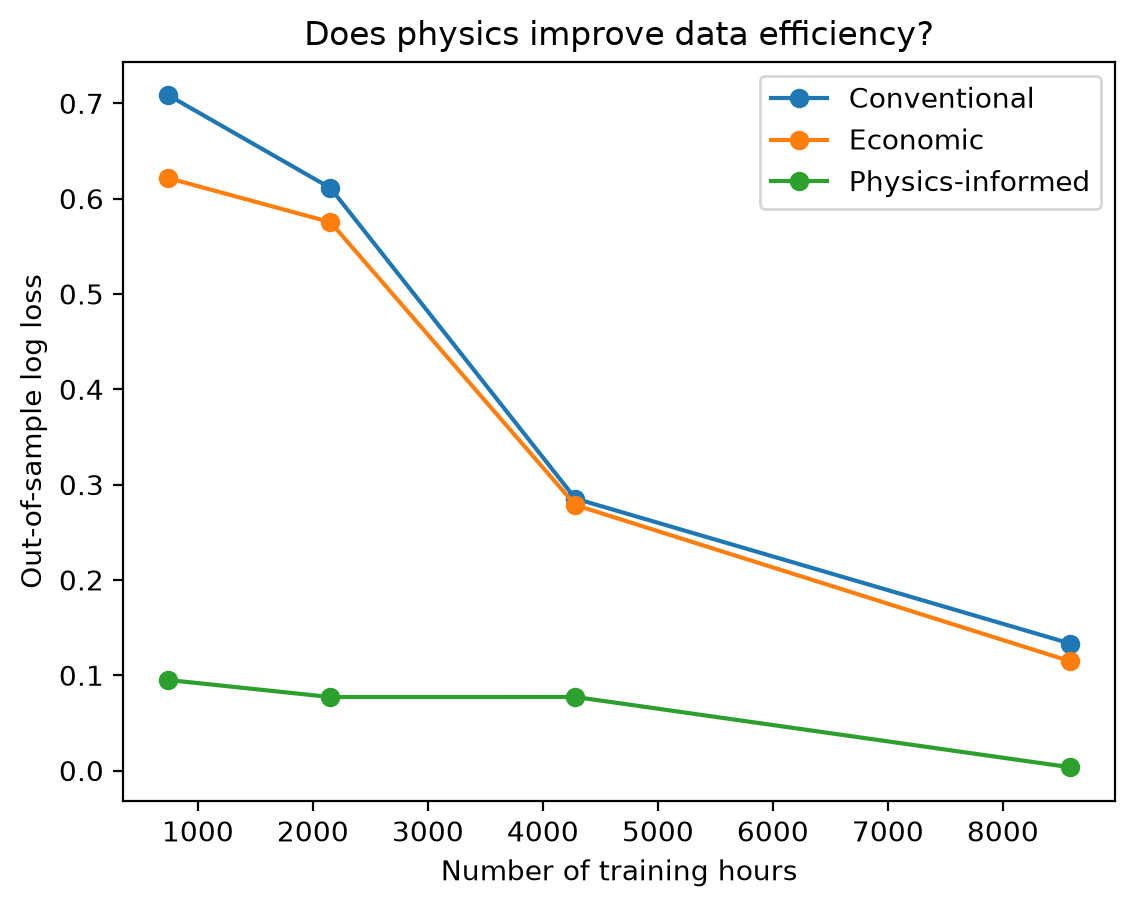

In [153]:
import matplotlib.pyplot as plt

for name, group in results_df.groupby("Model"):
    group = group.sort_values("N")
    plt.plot(
        group["N"],
        group["Log Loss"],
        marker="o",
        label=name
    )

plt.xlabel("Number of training hours")
plt.ylabel("Out-of-sample log loss")
plt.title("Does physics improve data efficiency?")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# replicated sample sizes - try different sample ranges and see if the efficiency holds up
feature_sets = {
    "Conventional": X_base,
    "Economic": X_econ,
    "Physics-informed": X_full
}

idx = y.dropna().index.sort_values()

for X in feature_sets.values():
    idx = idx.intersection(X.dropna().index)

train_idx = idx[idx.year == 2025]
test_idx = idx[idx.year == 2026]